In [1]:
import pandas as pd
import datetime
from datetime import datetime
import warnings 
warnings.filterwarnings('ignore')
from pydataset import datar

In [2]:
file_path = "/users/mac/Desktop/TB - NIMR.csv"
dataset= pd.read_csv(file_path)

In [3]:
print(dataset['DateofBirth'].head(10))

0    13/06/1972
1    04/05/1965
2    16/03/1966
3    15/05/1965
4    27/11/1958
5    17/05/1950
6    07/09/1960
7    16/10/1968
8    17/07/1964
9    17/08/1965
Name: DateofBirth, dtype: object


In [4]:
dataset['DateofBirth']=dataset['DateofBirth'].str.strip()

In [6]:
dataset['DateofBirth']=pd.to_datetime(dataset['DateofBirth'], format='%d/%m/%Y',errors='coerce')

In [7]:
def calculate_age(born):
    today = datetime.today()
    return today.year - born.year - ((today.month, today.day) < (born.month, born.day))
    

In [8]:
dataset.isna().sum()

PepID               0
VisitDate           0
Sex                 0
Education         172
DateofBirth         0
MaritalStatus       0
Occupation         11
TBPulDate         280
RiskFactors         7
TBPulYN             0
TBXPulDate       1531
TBXPulYN            2
dtype: int64

In [9]:
dataset['Age'] = dataset['DateofBirth'].apply(calculate_age)

In [10]:
dataset.isna().sum()

PepID               0
VisitDate           0
Sex                 0
Education         172
DateofBirth         0
MaritalStatus       0
Occupation         11
TBPulDate         280
RiskFactors         7
TBPulYN             0
TBXPulDate       1531
TBXPulYN            2
Age                 0
dtype: int64

In [11]:
import warnings 
warnings.filterwarnings('ignore')

In [12]:
from sklearn import preprocessing

In [13]:
import statsmodels.api as sm

In [14]:
import matplotlib.pyplot as plt

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
from sklearn.linear_model import LogisticRegression

In [17]:
from sklearn.metrics import classification_report

In [18]:
dataset.rename(columns={'TBXPulYN':'Diagnosis'},inplace=True)

In [19]:
dataset.isna().sum()

PepID               0
VisitDate           0
Sex                 0
Education         172
DateofBirth         0
MaritalStatus       0
Occupation         11
TBPulDate         280
RiskFactors         7
TBPulYN             0
TBXPulDate       1531
Diagnosis           2
Age                 0
dtype: int64

In [20]:
dataset.dropna(subset=['Diagnosis'],inplace=True)

In [21]:
dataset.isna().sum()

PepID               0
VisitDate           0
Sex                 0
Education         172
DateofBirth         0
MaritalStatus       0
Occupation         11
TBPulDate         280
RiskFactors         7
TBPulYN             0
TBXPulDate       1529
Diagnosis           0
Age                 0
dtype: int64

In [22]:
dataset.drop(['PepID','VisitDate','Education','Occupation','TBPulDate','RiskFactors','TBPulYN','TBXPulDate'],axis=1, inplace=True)

In [23]:
dataset.isna().sum()

Sex              0
DateofBirth      0
MaritalStatus    0
Diagnosis        0
Age              0
dtype: int64

In [24]:
dataset.info()
dataset = dataset.drop(columns=['DateofBirth'])

<class 'pandas.core.frame.DataFrame'>
Index: 1714 entries, 0 to 1715
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Sex            1714 non-null   object        
 1   DateofBirth    1714 non-null   datetime64[ns]
 2   MaritalStatus  1714 non-null   object        
 3   Diagnosis      1714 non-null   object        
 4   Age            1714 non-null   int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 80.3+ KB


In [25]:
numerical = dataset.select_dtypes(exclude=['object'])
categorical = dataset.select_dtypes(include=['object'])

In [26]:
numerical.head()

,Age
0,52
1,59
2,58
3,59
4,66


In [27]:
categorical.head()

,Sex,MaritalStatus,Diagnosis
0,Female,Single,No
1,Male,Married,No
2,Male,Single,No
3,Female,Married,No
4,Female,Married,No


In [28]:
le= preprocessing.LabelEncoder()

In [29]:
label_encoded_categorical = categorical.apply(le.fit_transform)

In [30]:
label_encoded_categorical = categorical.apply(le.fit_transform)

In [31]:
df= pd.concat([numerical, label_encoded_categorical], axis=1)

In [32]:
df.head()

,Age,Sex,MaritalStatus,Diagnosis
0,52,0,3,0
1,59,1,1,0
2,58,1,3,0
3,59,0,1,0
4,66,0,1,0


In [52]:
X= df.drop(['Diagnosis'], axis = 1)
Y= df.Diagnosis

In [53]:
logit_model = sm.Logit(Y,X)
result = logit_model.fit()
print(result.summary2())

Optimization terminated successfully.
         Current function value: 0.369551
         Iterations 6
                         Results: Logit
Model:              Logit            Method:           MLE      
Dependent Variable: Diagnosis        Pseudo R-squared: -0.006   
Date:               2024-11-28 06:57 AIC:              1272.8218
No. Observations:   1714             BIC:              1289.1616
Df Model:           2                Log-Likelihood:   -633.41  
Df Residuals:       1711             LL-Null:          -629.55  
Converged:          1.0000           LLR p-value:      1.0000   
No. Iterations:     6.0000           Scale:            1.0000   
----------------------------------------------------------------
                 Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
----------------------------------------------------------------
Age             -0.0395   0.0031 -12.6348 0.0000 -0.0456 -0.0333
Sex              0.2453   0.1539   1.5939 0.1110 -0.0563  0.5468
MaritalStatus

In [35]:
X = X.drop(['Sex','MaritalStatus'], axis = 1)

In [36]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)

In [37]:
model = LogisticRegression()

In [38]:
model.fit(X_train, Y_train)

LogisticRegression()

In [39]:
print("Accuracy of the logistic regression model: {:.2f}".format(model.score(X_test,Y_test)))

Accuracy of the logistic regression model: 0.87


In [40]:
Y_pred = model.predict(X_test)

In [41]:
print(classification_report(Y_test, Y_pred))
import pandas as pd
from sklearn.metrics import confusion_matrix  # Ensure confusion_matrix is imported
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


              precision    recall  f1-score   support

           0       0.87      1.00      0.93       449
           1       0.00      0.00      0.00        66

    accuracy                           0.87       515
   macro avg       0.44      0.50      0.47       515
weighted avg       0.76      0.87      0.81       515



In [42]:
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

# Fit the logistic regression model
model = LogisticRegression()
model.fit(X_train, Y_train)

# Predict class labels
Y_pred = model.predict(X_test)

# Generate confusion matrix
tn, fp, fn, tp = confusion_matrix(Y_test, Y_pred).ravel()

# Output the results
print(f'True Positives (TP): {tp}')
print(f'True Negatives (TN): {tn}')
print(f'False Positives (FP): {fp}')
print(f'False Negatives (FN): {fn}')

True Positives (TP): 0
True Negatives (TN): 451
False Positives (FP): 0
False Negatives (FN): 64


In [54]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=100)

# Fit the logistic regression model
model = LogisticRegression()
model.fit(X_train, Y_train)

# Predict probabilities (specifically for the positive class)
Y_probs = model.predict_proba(X_test)[:, 1]

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Output the AUC value
print(f'AUC: {auc}')

AUC: 0.5473105216980495


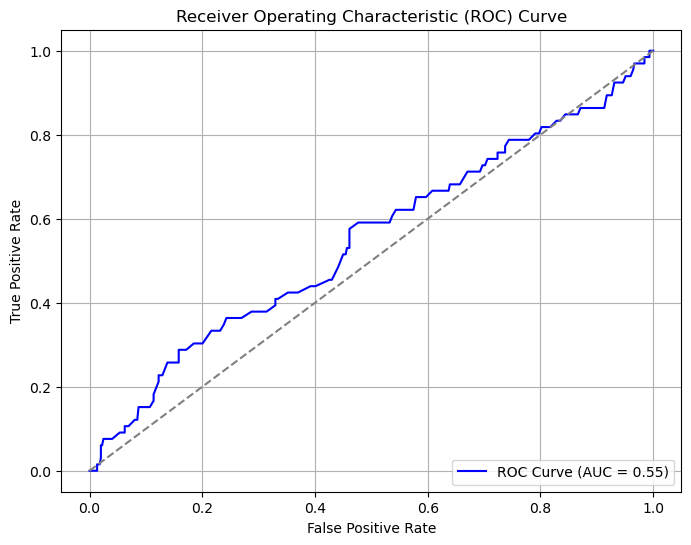

In [55]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=100)

# Fit the logistic regression model
model = LogisticRegression()
model.fit(X_train, Y_train)

# Predict probabilities (for the positive class)
Y_probs = model.predict_proba(X_test)[:, 1]

# Compute False Positive Rate (FPR), True Positive Rate (TPR), and thresholds
fpr, tpr, thresholds = roc_curve(Y_test, Y_probs)

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random classifier)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [57]:
knn= KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, Y_train)

KNeighborsClassifier()

Accuracy: 0.86
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.98      0.92       449
           1       0.29      0.06      0.10        66

    accuracy                           0.86       515
   macro avg       0.58      0.52      0.51       515
weighted avg       0.80      0.86      0.82       515

Confusion Matrix:
[[439  10]
 [ 62   4]]
AUC: 0.5127218735236554


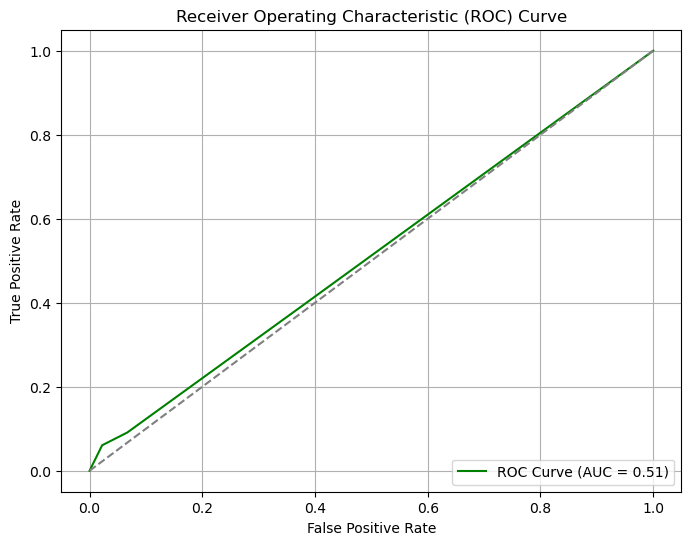

In [64]:
# Make predictions on the test set
Y_pred = knn.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(Y_test, Y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Detailed classification report
print("Classification Report:")
print(classification_report(Y_test, Y_pred))

# Confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))
from sklearn.metrics import roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)

# Fit the logistic regression model
knn= KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, Y_train)



# Predict probabilities (specifically for the positive class)
Y_probs = knn.predict_proba(X_test)[:, 1]

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Output the AUC value
print(f'AUC: {auc}')

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)


# Fit the logistic regression model
knn= KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, Y_train)

# Predict probabilities (for the positive class)
Y_probs = knn.predict_proba(X_test)[:, 1]

# Compute False Positive Rate (FPR), True Positive Rate (TPR), and thresholds
fpr, tpr, thresholds = roc_curve(Y_test, Y_probs)

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='green', label=f'ROC Curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random classifier)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [47]:
clf=GaussianNB()
clf.fit(X_train, Y_train)

GaussianNB()

In [48]:
Y_pred=clf.predict(X_test)
print(classification_report(Y_test,Y_pred))

              precision    recall  f1-score   support

           0       0.88      1.00      0.93       451
           1       0.00      0.00      0.00        64

    accuracy                           0.88       515
   macro avg       0.44      0.50      0.47       515
weighted avg       0.77      0.88      0.82       515



In [59]:
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)
# Fit the logistic regression model

clf=GaussianNB()
clf.fit(X_train, Y_train)

# Predict class labels
Y_pred=clf.predict(X_test)

# Generate confusion matrix
tn, fp, fn, tp = confusion_matrix(Y_test, Y_pred).ravel()

# Output the results
print(f'True Positives (TP): {tp}')
print(f'True Negatives (TN): {tn}')
print(f'False Positives (FP): {fp}')
print(f'False Negatives (FN): {fn}')


True Positives (TP): 0
True Negatives (TN): 449
False Positives (FP): 0
False Negatives (FN): 66


In [60]:
from sklearn.metrics import roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)

# Fit the logistic regression model
clf=GaussianNB()
clf.fit(X_train, Y_train)


# Predict probabilities (specifically for the positive class)
Y_probs = clf.predict_proba(X_test)[:, 1]

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Output the AUC value
print(f'AUC: {auc}')

AUC: 0.5709657825470743


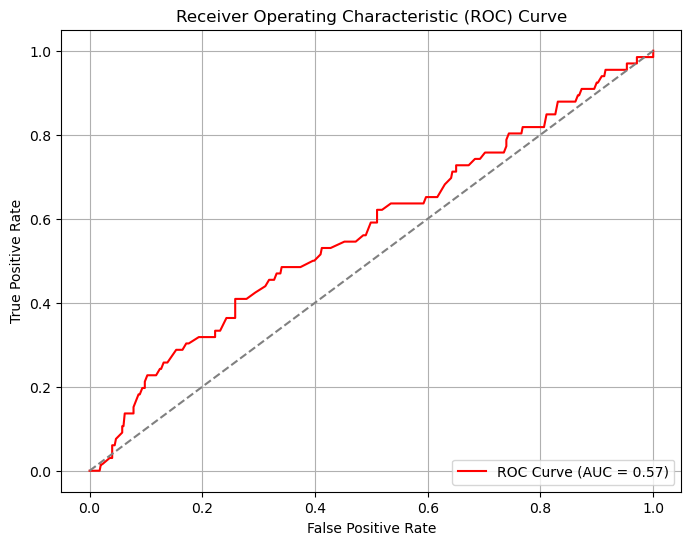

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

# Assuming X is your feature matrix and y is your target variable
# Split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.3, random_state=100)


# Fit the logistic regression model
clf=GaussianNB()
clf.fit(X_train, Y_train)

# Predict probabilities (for the positive class)
Y_probs = clf.predict_proba(X_test)[:, 1]

# Compute False Positive Rate (FPR), True Positive Rate (TPR), and thresholds
fpr, tpr, thresholds = roc_curve(Y_test, Y_probs)

# Calculate AUC
auc = roc_auc_score(Y_test, Y_probs)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='red', label=f'ROC Curve (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Diagonal line (random classifier)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()